/tmp/ipykernel_1326/2355985715.py:38: RuntimeWarning: overflow encountered in exp
  def alpha_m(V): return 0.1 * (V + 40) / (1 - np.exp(-(V + 40) / 10))
/tmp/ipykernel_1326/2355985715.py:39: RuntimeWarning: overflow encountered in exp
  def beta_m(V): return 4.0 * np.exp(-(V + 65) / 18)
/tmp/ipykernel_1326/2355985715.py:40: RuntimeWarning: overflow encountered in exp
  def alpha_h(V): return 0.07 * np.exp(-(V + 65) / 20)
/tmp/ipykernel_1326/2355985715.py:41: RuntimeWarning: overflow encountered in exp
  def beta_h(V): return 1 / (1 + np.exp(-(V + 35) / 10))
/tmp/ipykernel_1326/2355985715.py:36: RuntimeWarning: overflow encountered in exp
  def alpha_n(V): return 0.01 * (V + 55) / (1 - np.exp(-(V + 55) / 10))
/tmp/ipykernel_1326/2355985715.py:37: RuntimeWarning: overflow encountered in exp
  def beta_n(V): return 0.125 * np.exp(-(V + 65) / 80)
/tmp/ipykernel_1326/2355985715.py:38: RuntimeWarning: invalid value encountered in scalar divide
  def alpha_m(V): return 0.1 * (V + 40) / (1 - n

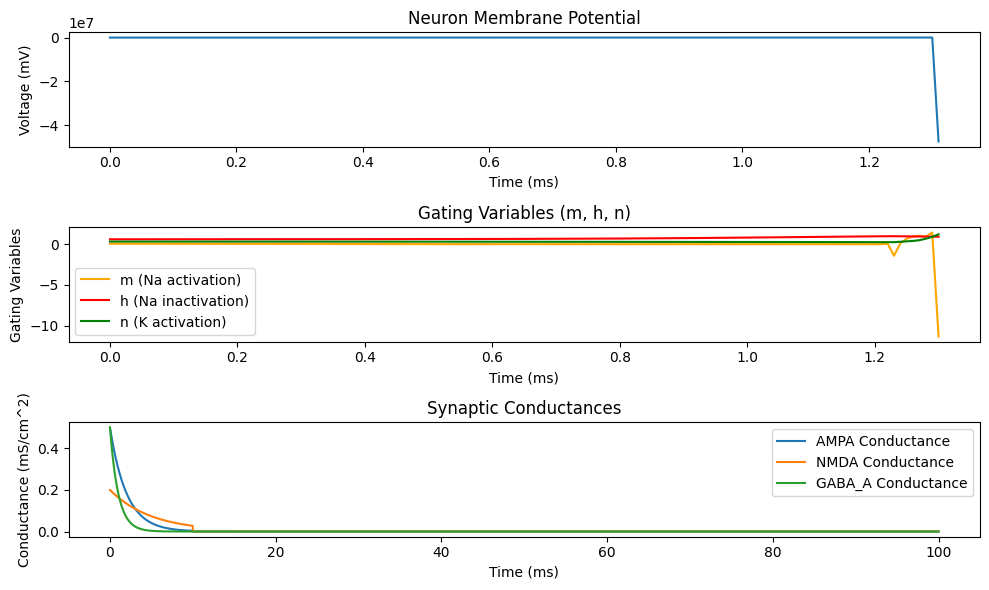

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Constants
C_m = 1.0  # Membrane capacitance (uF/cm^2)
g_Na_max = 120.0  # Max Na conductance (mS/cm^2)
g_K_max = 36.0  # Max K conductance (mS/cm^2)
g_L = 0.3  # Leak conductance (mS/cm^2)
E_Na = 50.0  # Na reversal potential (mV)
E_K = -77.0  # K reversal potential (mV)
E_L = -54.387  # Leak reversal potential (mV)
E_AMPA = 0  # AMPA reversal potential (mV)
E_NMDA = 0  # NMDA reversal potential (mV)
E_GABA_A = -70.0  # GABA_A reversal potential (mV)

# Synaptic dynamics parameters
g_AMPA_max = 0.5  # Max AMPA conductance (mS/cm^2)
g_NMDA_max = 0.2  # Max NMDA conductance (mS/cm^2)
g_GABA_A_max = 0.5  # Max GABA_A conductance (mS/cm^2)

# Time settings
dt = 0.01  # Time step (ms)
T = 100  # Total simulation time (ms)
time = np.arange(0, T, dt)  # Time array

# Initial values
V = -65.0  # Membrane potential (mV)
m = 0.05  # Na activation gating variable
h = 0.6  # Na inactivation gating variable
n = 0.32  # K activation gating variable
AMPA = 0.0  # AMPA synaptic conductance
NMDA = 0.0  # NMDA synaptic conductance
GABA_A = 0.0  # GABA_A synaptic conductance

# Functions for gating variables (alpha and beta rates)
def alpha_n(V): return 0.01 * (V + 55) / (1 - np.exp(-(V + 55) / 10))
def beta_n(V): return 0.125 * np.exp(-(V + 65) / 80)
def alpha_m(V): return 0.1 * (V + 40) / (1 - np.exp(-(V + 40) / 10))
def beta_m(V): return 4.0 * np.exp(-(V + 65) / 18)
def alpha_h(V): return 0.07 * np.exp(-(V + 65) / 20)
def beta_h(V): return 1 / (1 + np.exp(-(V + 35) / 10))

# Synaptic conductances (e.g., simple step inputs)
def synaptic_AMPA(t): return g_AMPA_max * np.exp(-t / 2.0) if t < 10 else 0
def synaptic_NMDA(t): return g_NMDA_max * np.exp(-t / 5.0) if t < 10 else 0
def synaptic_GABA_A(t): return g_GABA_A_max * np.exp(-t / 1.0) if t < 10 else 0

# HH model with synaptic conductances
def dV(V, m, h, n, AMPA, NMDA, GABA_A, t):
    I_Na = g_Na_max * m**3 * h * (V - E_Na)  # Sodium current
    I_K = g_K_max * n**4 * (V - E_K)  # Potassium current
    I_L = g_L * (V - E_L)  # Leak current

    # Synaptic currents
    I_AMPA = AMPA * (V - E_AMPA)
    I_NMDA = NMDA * (V - E_NMDA)
    I_GABA_A = GABA_A * (V - E_GABA_A)
    
    I_syn = I_AMPA + I_NMDA + I_GABA_A  # Total synaptic current
    
    dV = (I_Na + I_K + I_L + I_syn) / C_m  # Membrane voltage derivative
    return dV

# Differential equations for gating variables
def dm(V, m): return alpha_m(V) * (1 - m) - beta_m(V) * m
def dh(V, h): return alpha_h(V) * (1 - h) - beta_h(V) * h
def dn(V, n): return alpha_n(V) * (1 - n) - beta_n(V) * n

# Simulation loop
V_arr = []
m_arr, h_arr, n_arr = [], [], []
for t in time:
    dVdt = dV(V, m, h, n, AMPA, NMDA, GABA_A, t)
    V += dVdt * dt  # Update membrane potential
    m += dm(V, m) * dt  # Update gating variable m
    h += dh(V, h) * dt  # Update gating variable h
    n += dn(V, n) * dt  # Update gating variable n

    # Synaptic input
    AMPA = synaptic_AMPA(t)
    NMDA = synaptic_NMDA(t)
    GABA_A = synaptic_GABA_A(t)

    # Store results for plotting
    V_arr.append(V)
    m_arr.append(m)
    h_arr.append(h)
    n_arr.append(n)

# Plotting results
plt.figure(figsize=(10, 6))
plt.subplot(3, 1, 1)
plt.plot(time, V_arr, label="Membrane Potential (mV)")
plt.xlabel("Time (ms)")
plt.ylabel("Voltage (mV)")
plt.title("Neuron Membrane Potential")

plt.subplot(3, 1, 2)
plt.plot(time, m_arr, label="m (Na activation)", color="orange")
plt.plot(time, h_arr, label="h (Na inactivation)", color="red")
plt.plot(time, n_arr, label="n (K activation)", color="green")
plt.xlabel("Time (ms)")
plt.ylabel("Gating Variables")
plt.title("Gating Variables (m, h, n)")
plt.legend()

plt.subplot(3, 1, 3)
plt.plot(time, [synaptic_AMPA(t) for t in time], label="AMPA Conductance")
plt.plot(time, [synaptic_NMDA(t) for t in time], label="NMDA Conductance")
plt.plot(time, [synaptic_GABA_A(t) for t in time], label="GABA_A Conductance")
plt.xlabel("Time (ms)")
plt.ylabel("Conductance (mS/cm^2)")
plt.title("Synaptic Conductances")
plt.legend()

plt.tight_layout()
plt.show()
